# Scam Message Detector: Capstone Project

**Problem statement.** Scam texts (fake prizes, urgent "call now" messages, suspicious links) trick people into paying or sharing details. Can a model read a text message and flag it as a scam, **and show which words made it suspicious**?

**Pipeline in this notebook:** load data → clean → explore (EDA) → build features → compare models → tune → evaluate on a held-out test set → explain predictions → save the model for the Flask app.

**Data:** the *SMS Spam Collection* (about 5.5k real text messages labelled `ham` = normal or `spam` = scam/junk). Save it as `data/spam.csv` and start Jupyter from the project folder, so `import spamlib` and the data path work.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split

import spamlib   # cleaning, text preprocessing and explanation code shared with train.py and the app

pd.set_option("display.max_colwidth", 120)
DATA_PATH = Path("data/spam.csv")

## 1. Load the data

In [2]:
raw = spamlib.load_data(DATA_PATH)
print("shape:", raw.shape)
display(raw.head())
print(raw["label"].value_counts())

shape: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


label
ham     4825
spam     747
Name: count, dtype: int64


## 2. Clean the data
`clean_data` (in `spamlib.py`) does four things:
1. drops rows with a missing label or empty text and keeps only `ham` / `spam` labels
2. removes **exact duplicate** messages
3. removes messages that appear with **two different labels** (we can't tell which label is right)
4. adds `label_num` (spam = 1, ham = 0)

Duplicates are removed **before** the train/test split. If the same message were in both sets, the test score would look better than it really is (data leakage).

In [3]:
df, log = spamlib.clean_data(raw)
display(pd.Series(log, name="rows"))

rows_loaded                       5572
rows_after_dropping_bad_rows      5572
exact_duplicates_removed           414
conflicting_label_rows_removed       0
rows_final                        5158
Name: rows, dtype: int64

## 3. Explore the data (EDA)
### 3.1 Class balance

label
ham     87.6
spam    12.4
Name: count, dtype: float64


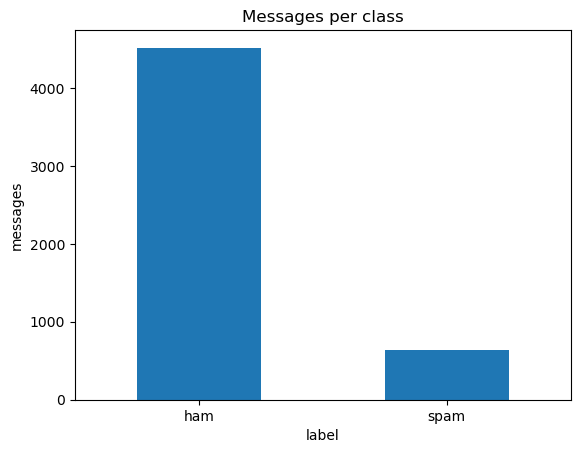

In [4]:
counts = df["label"].value_counts()
print((counts / len(df) * 100).round(1))
ax = counts.plot(kind="bar", title="Messages per class")
ax.set_ylabel("messages")
plt.xticks(rotation=0)
plt.show()

The classes are **imbalanced**: most messages are normal. A model that says "ham" every time would already look accurate, so **accuracy is a poor metric here**. We use **precision** (of the messages flagged as scams, how many really are?) and **recall** (of all scams, how many did we catch?), and combine them as **F1**.

### 3.2 Length and capital letters

,chars,words,caps_ratio
label,,,
ham,70.42,14.13,0.06
spam,137.59,23.64,0.11


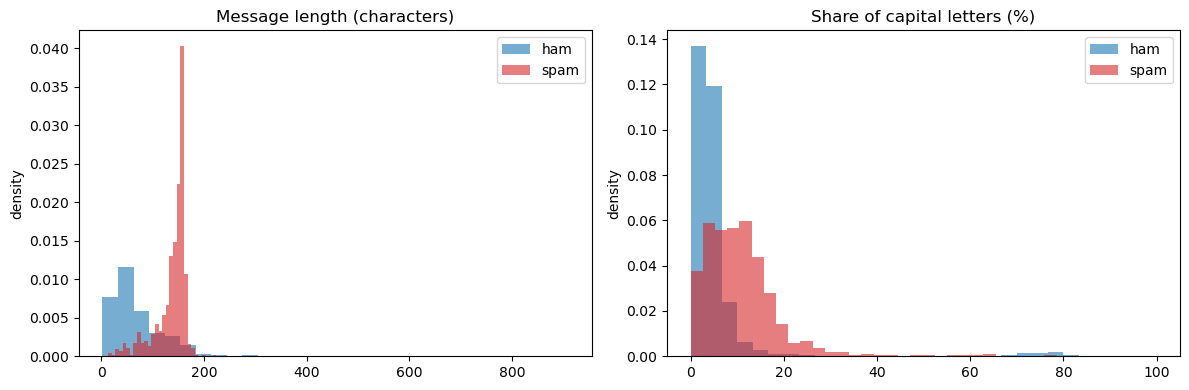

In [5]:
eda = df.copy()
eda["chars"] = eda["text"].str.len()
eda["words"] = eda["text"].str.split().str.len()
eda["caps_ratio"] = eda["text"].apply(lambda t: sum(c.isupper() for c in t) / max(len(t), 1))
eda["has_link"] = eda["text"].str.contains(spamlib.URL_RE)
eda["has_money_symbol"] = eda["text"].str.contains(spamlib.CURRENCY_RE)
eda["has_long_number"] = eda["text"].str.contains(spamlib.LONG_NUMBER_RE)

display(eda.groupby("label")[["chars", "words", "caps_ratio"]].mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, color in [("ham", "tab:blue"), ("spam", "tab:red")]:
    part = eda[eda["label"] == label]
    axes[0].hist(part["chars"], bins=30, alpha=0.6, density=True, label=label, color=color)
    axes[1].hist(part["caps_ratio"] * 100, bins=30, alpha=0.6, density=True, label=label, color=color)
axes[0].set_title("Message length (characters)")
axes[1].set_title("Share of capital letters (%)")
for ax in axes:
    ax.set_ylabel("density")
    ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Scam signals: links, money symbols, long numbers

,has_link,has_money_symbol,has_long_number
label,,,
ham,0.0,0.4,0.1
spam,13.7,33.3,73.4


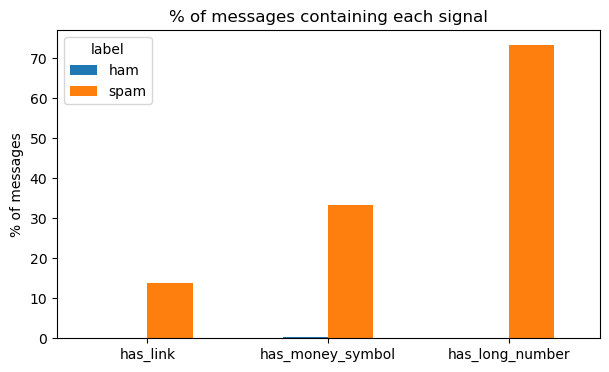

In [6]:
rates = eda.groupby("label")[["has_link", "has_money_symbol", "has_long_number"]].mean().mul(100)
display(rates.round(1))
rates.T.plot(kind="bar", figsize=(7, 4), title="% of messages containing each signal")
plt.ylabel("% of messages")
plt.xticks(rotation=0)
plt.show()

These three signals are exactly what `spamlib.normalize_text` turns into special words (`urltoken`, `currencytoken`, `numbertoken`), so the model can learn them even though every phone number and link is different.

### 3.4 Most common words in each class

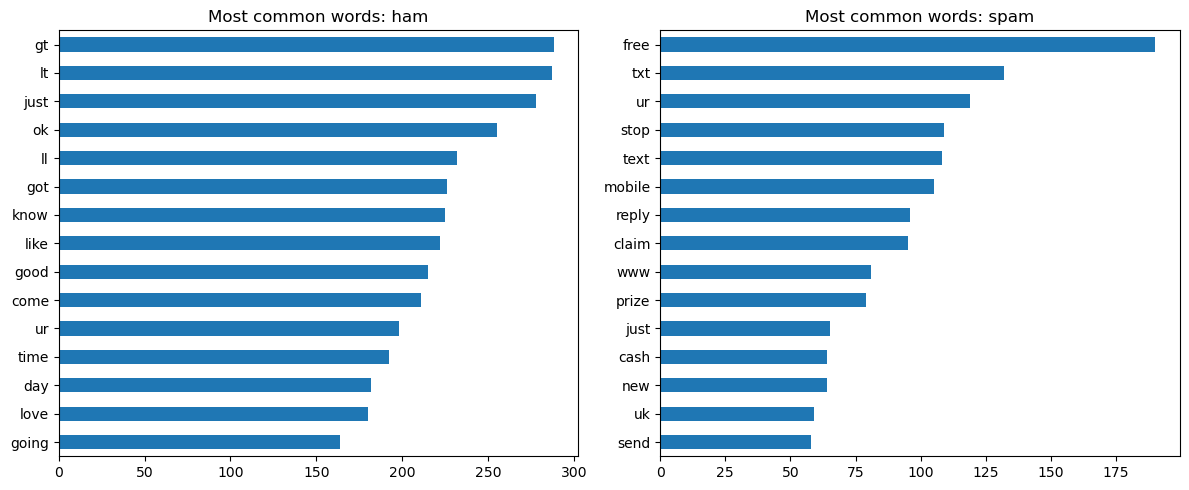

In [7]:
def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
    counts = np.asarray(cv.fit_transform(texts).sum(axis=0)).ravel()
    order = counts.argsort()[::-1][:n]
    return pd.Series(counts[order], index=cv.get_feature_names_out()[order])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, label in zip(axes, ["ham", "spam"]):
    top_words(df.loc[df["label"] == label, "text"]).iloc[::-1].plot(
        kind="barh", ax=ax, title=f"Most common words: {label}")
plt.tight_layout()
plt.show()

## 4. Split and build features
- **Split:** 80% train / 20% test, `stratify` keeps the same spam share in both. The test set is used **once**, at the end.
- **Features:** TF-IDF on single words and word pairs. TF-IDF gives high weight to words that are frequent in a message but rare overall.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label_num"], test_size=0.2,
    stratify=df["label_num"], random_state=spamlib.RANDOM_STATE)
print("train:", len(X_train), "| test:", len(X_test))
print("spam share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

example = "WIN £1000 now! Call 09061701461 or visit www.claim-prize.com"
print()
print("before:", example)
print("after :", spamlib.normalize_text(example))

train: 4126 | test: 1032
spam share  train: 0.125  test: 0.124

before: WIN £1000 now! Call 09061701461 or visit www.claim-prize.com
after : win  currencytoken 1000 now! call  numbertoken  or visit  urltoken 


## 5. Compare models
Same features, three classifiers, **5-fold cross-validation on the training set only**.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=spamlib.RANDOM_STATE)

rows = []
for name, clf in spamlib.candidate_models().items():
    s = cross_validate(spamlib.build_pipeline(clf), X_train, y_train, cv=cv,
                       scoring=["precision", "recall", "f1"])
    rows.append({"model": name,
                 "precision": s["test_precision"].mean(),
                 "recall": s["test_recall"].mean(),
                 "f1": s["test_f1"].mean()})

cv_results = pd.DataFrame(rows).set_index("model").round(3)
display(cv_results.sort_values("f1", ascending=False))

,precision,recall,f1
model,,,
Naive Bayes,0.992,0.916,0.952
Logistic Regression,0.970,0.926,0.947
Linear SVM,0.980,0.913,0.944


**Choosing the final model.** Models like these usually score close to each other on this kind of data. We ship **logistic regression** because it gives every word a weight, which lets the app explain *why* a message was flagged. Look at the table above: if another model is clearly better, that is a real trade-off between accuracy and explainability to discuss.

## 6. Tune logistic regression
`C` controls how strongly the model is kept from overfitting (smaller = simpler). We try four values and keep the best F1.

In [10]:
grid = GridSearchCV(
    spamlib.build_pipeline(LogisticRegression(class_weight="balanced", max_iter=1000)),
    param_grid={"clf__C": [0.1, 1, 10, 100]},
    scoring="f1", cv=cv)
grid.fit(X_train, y_train)

display(pd.DataFrame(grid.cv_results_)[["param_clf__C", "mean_test_score"]].round(3))
print("Best C:", grid.best_params_["clf__C"])
final = grid.best_estimator_   # already refit on the whole training set

,param_clf__C,mean_test_score
0,0.1,0.925
1,1.0,0.941
2,10.0,0.947
3,100.0,0.939


Best C: 10


## 7. Final evaluation on the test set
The first and only time the test set is used.

              precision    recall  f1-score   support

         ham      0.993     0.994     0.994       904
        spam      0.961     0.953     0.957       128

    accuracy                          0.989      1032
   macro avg      0.977     0.974     0.975      1032
weighted avg      0.989     0.989     0.989      1032



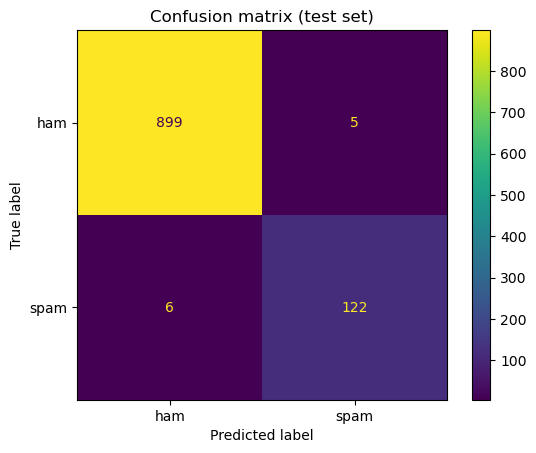

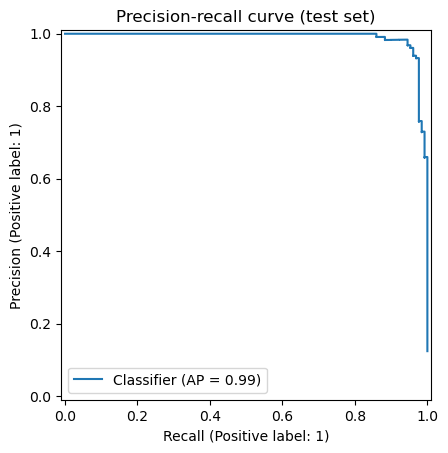

In [11]:
THRESHOLD = 0.5
proba = final.predict_proba(X_test)[:, 1]
pred = (proba >= THRESHOLD).astype(int)

print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["ham", "spam"])
plt.title("Confusion matrix (test set)")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, proba)
plt.title("Precision-recall curve (test set)")
plt.show()

**Which mistake is worse?** A *false positive* (a real message flagged as a scam) can hide something important, like a bank code or a delivery notice. A *false negative* (a scam slips through) is dangerous too. The precision-recall curve shows how one trades against the other if you move the threshold away from 0.5.

## 8. Error analysis: what does the model get wrong?

In [12]:
errors = pd.DataFrame({"text": X_test.values, "true": y_test.values, "score": proba.round(3)})
false_pos = errors[(errors["true"] == 0) & (errors["score"] >= THRESHOLD)]
false_neg = errors[(errors["true"] == 1) & (errors["score"] < THRESHOLD)]

print(f"{len(false_pos)} false positives (normal messages flagged as scams)")
display(false_pos.head(5))
print(f"{len(false_neg)} false negatives (scams that slipped through)")
display(false_neg.head(5))

5 false positives (normal messages flagged as scams)


,text,true,score
18,Ok... Ur typical reply...,0,0.508
241,Host-based IDPS for linux systems.,0,0.583
951,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May",0,0.893
977,Waiting for your call.,0,0.835
1001,K k:) sms chat with me.,0,0.557


6 false negatives (scams that slipped through)


,text,true,score
323,Sorry! U can not unsubscribe yet. THE MOB offer package has a min term of 54 weeks> pls resubmit request after expir...,1,0.306
389,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,1,0.107
636,thesmszone.com lets you send free anonymous and masked messages..im sending this message from there..do you see the ...,1,0.447
848,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do yo...,1,0.078
921,"Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all...",1,0.094


*Write your own observations here after you have seen the real errors* (for example: are the missed scams short? do they avoid the usual scam words?).

## 9. Explain the model: which words matter most?

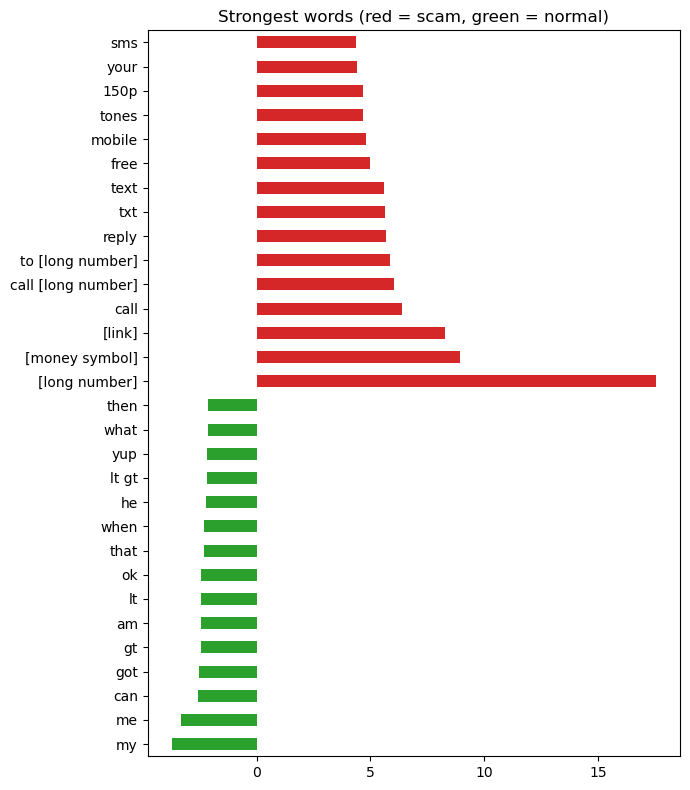

In [13]:
vec = final.named_steps["tfidf"]
names = vec.get_feature_names_out()
coef = final.named_steps["clf"].coef_[0]
order = coef.argsort()

top_scam = order[::-1][:15]
top_safe = order[:15]
weights = pd.concat([
    pd.Series(coef[top_safe], index=[spamlib.pretty_term(names[i]) for i in top_safe]),
    pd.Series(coef[top_scam], index=[spamlib.pretty_term(names[i]) for i in top_scam]),
])
colors = ["tab:green" if w < 0 else "tab:red" for w in weights]
weights.plot(kind="barh", figsize=(7, 8), color=colors,
             title="Strongest words (red = scam, green = normal)")
plt.tight_layout()
plt.show()

In [14]:
bundle = {"pipeline": final, "threshold": THRESHOLD}

samples = [
    "URGENT! You have won a £1000 cash prize. Call 09012345678 now or visit www.claim-prize-now.com to collect.",
    "Hey, are we still meeting at 6 for dinner? I will bring the umbrella.",
]
for msg in samples:
    r = spamlib.predict_message(bundle, msg, names)
    print(msg)
    print(f"  scam score: {r['score']:.2f}  ->  {'SCAM' if r['is_scam'] else 'safe'}")
    print("  pushes towards scam:", [s['term'] for s in r['spam_signals']])
    print("  pushes towards safe:", [s['term'] for s in r['safe_signals']])
    print()

URGENT! You have won a £1000 cash prize. Call 09012345678 now or visit www.claim-prize-now.com to collect.
  scam score: 1.00  ->  SCAM
  pushes towards scam: ['[long number]', '[link]', '[money symbol]', 'call [long number]', 'call']
  pushes towards safe: ['you']

Hey, are we still meeting at 6 for dinner? I will bring the umbrella.
  scam score: 0.01  ->  safe
  pushes towards scam: ['for', 'are']
  pushes towards safe: ['hey', 'still', 'at', 'dinner', 'meeting']



## 10. Save the model for the Flask app

In [15]:
Path("models").mkdir(exist_ok=True)
joblib.dump(bundle, "models/scam_model.joblib")
print("Saved models/scam_model.joblib")

Saved models/scam_model.joblib


## 11. Limitations and what I would improve with more time
- **Old, narrow data.** The dataset is from the 2000s and mostly UK text messages. Today's scams (fake delivery notices, bank phishing, "wrong number" chats) look different, so the model will miss many of them. The best next step is adding a modern smishing/phishing dataset.
- **Threshold.** 0.5 is a default. Choose it on purpose, based on which mistake costs more.
- **Better features.** Try character n-grams (catches misspelled scam words like "fr33") and sender or time information if available.
- **Stronger models.** Compare a small transformer model, keeping logistic regression as the explainable baseline.
- **Calibration and monitoring.** Check that scores behave like probabilities and keep collecting new misclassified messages.